<a href="https://colab.research.google.com/github/alvarocoronaj/CC.MSCA2102FLE.B03.202630.1_al07183971---Modulo02_T04/blob/main/CC_MSCA2102FLE_B03_202630_1_al07183971_Modulo02_T04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
!nvidia-smi

Thu Oct 15 03:15:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   77C    P0             33W /   70W |     757MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [14]:
import subprocess
import sys
import matplotlib.pyplot as plt
import seaborn as sns

# Dynamic installation of packages if missing to prevent ModuleNotFoundError
try:
    import evaluate
    import datasets
    import transformers
except ImportError:
    print("Installing missing dependencies...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers", "datasets", "evaluate", "scikit-learn"])

import time
import torch
import numpy as np
import pandas as pd
from PIL import Image
import requests
from huggingface_hub import login
from transformers import pipeline, AutoTokenizer, AutoModelForSequenceClassification, AutoProcessor, AutoModelForZeroShotImageClassification
from datasets import load_dataset
import evaluate
from sklearn.metrics import accuracy_score, precision_recall_fscore_support


In [15]:
def installDependencies():
    # Instalación programática de las bibliotecas requeridas para la ejecución
    import subprocess
    import sys
    requiredPackages = [
        "transformers",
        "datasets",
        "evaluate",
        "scikit-learn",
        "torch",
        "pillow",
        "requests",
        "huggingface_hub",
        "pandas"
    ]
    for pkg in requiredPackages:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
    print("Dependencias instaladas exitosamente.")

In [16]:
def authenticateHuggingFace(apiToken=None):
    # Inicio de sesión en el Hub de Hugging Face mediante token de API
    if apiToken:
        login(token=apiToken)
        print("Autenticación completada en Hugging Face Hub.")
    else:
        print("Token no proporcionado. Ejecutando en modo de acceso público.")

In [17]:
def evaluateNlpModel():
    # Carga de modelo de NLP para clasificación de texto y evaluación estadística
    print("\n--- Ejecutando Benchmark de Procesamiento de Lenguaje Natural ---")
    modelCheckpoint = "distilbert-base-uncased-finetuned-sst-2-english"
    nlpTokenizer = AutoTokenizer.from_pretrained(modelCheckpoint)
    nlpModel = AutoModelForSequenceClassification.from_pretrained(modelCheckpoint)
    nlpPipeline = pipeline("text-classification", model=nlpModel, tokenizer=nlpTokenizer)

    # Carga de muestras del dataset SST-2
    evalDataset = load_dataset("stanfordnlp/sst2", split="validation[:50]")
    inputTexts = evalDataset["sentence"]
    targetLabels = evalDataset["label"] # 0: NEGATIVE, 1: POSITIVE

    predictedLabels = []
    latencyMeasurements = []

    # Inferencia iterativa y registro de latencia
    for text in inputTexts:
        startTime = time.perf_counter()
        pipelineOutput = nlpPipeline(text)[0]
        endTime = time.perf_counter()

        elapsedMs = (endTime - startTime) * 1000.0
        latencyMeasurements.append(elapsedMs)

        labelNumeric = 1 if pipelineOutput["label"] == "POSITIVE" else 0
        predictedLabels.append(labelNumeric)

    # Computación de métricas de calidad predictiva
    accuracyVal = accuracy_score(targetLabels, predictedLabels)
    precisionVal, recallVal, f1Val, _ = precision_recall_fscore_support(targetLabels, predictedLabels, average="weighted")
    averageLatencyMs = float(np.mean(latencyMeasurements))

    print(f"NLP - Accuracy: {accuracyVal:.4f} | Precision: {precisionVal:.4f} | Recall: {recallVal:.4f} | F1-Score: {f1Val:.4f}")
    print(f"NLP - Latencia Media: {averageLatencyMs:.2f} ms")

    return {
        "paradigm": "NLP (Texto)",
        "modelName": modelCheckpoint,
        "accuracy": accuracyVal,
        "precision": precisionVal,
        "recall": recallVal,
        "f1Score": f1Val,
        "latencyMs": averageLatencyMs
    }

In [18]:
def evaluateVisionModel():
    # Carga de modelo de Visión por Computadora y clasificación de imágenes
    print("\n--- Ejecutando Benchmark de Visión por Computadora ---")
    modelCheckpoint = "google/vit-base-patch16-224"
    visionPipeline = pipeline("image-classification", model=modelCheckpoint)

    # Muestras de imágenes para prueba de inferencia
    imageUrls = [
        "http://images.cocodataset.org/val2017/000000039769.jpg",
        "https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/cats.replica.png"
    ]
    groundTruthLabels = ["tabby, tabby cat", "Egyptian cat"]

    predictedLabels = []
    latencyMeasurements = []

    for url, groundTruth in zip(imageUrls, groundTruthLabels):
        try:
            # Fetch image with a timeout to prevent hanging
            response = requests.get(url, stream=True, timeout=10)
            response.raise_for_status()
            rawImage = Image.open(response.raw).convert("RGB")
        except Exception as e:
            print(f"Advertencia: No se pudo cargar la imagen {url}. Error: {e}")
            # Fallback to a blank image so the evaluation doesn't crash
            rawImage = Image.new("RGB", (224, 224), color="gray")

        startTime = time.perf_counter()
        predictions = visionPipeline(rawImage)
        endTime = time.perf_counter()

        elapsedMs = (endTime - startTime) * 1000.0
        latencyMeasurements.append(elapsedMs)
        predictedLabels.append(predictions[0]["label"] if predictions else "")

    # Evaluación de correspondencia semántica
    matchCount = sum([1 for trueL, predL in zip(groundTruthLabels, predictedLabels) if trueL.lower() in predL.lower() or predL.lower() in trueL.lower()])
    accuracyVal = matchCount / len(groundTruthLabels)
    precisionVal = accuracyVal
    recallVal = accuracyVal
    f1Val = accuracyVal
    averageLatencyMs = float(np.mean(latencyMeasurements)) if latencyMeasurements else 0.0

    print(f"Visión - Accuracy: {accuracyVal:.4f} | Precision: {precisionVal:.4f} | Recall: {recallVal:.4f} | F1-Score: {f1Val:.4f}")
    print(f"Visión - Latencia Media: {averageLatencyMs:.2f} ms")

    return {
        "paradigm": "Visión por Computadora",
        "modelName": modelCheckpoint,
        "accuracy": accuracyVal,
        "precision": precisionVal,
        "recall": recallVal,
        "f1Score": f1Val,
        "latencyMs": averageLatencyMs
    }

In [19]:
def evaluateMultimodalModel():
    # Carga de arquitectura multimodal CLIP para clasificación Zero-Shot
    print("\n--- Ejecutando Benchmark Multimodal Zero-Shot ---")
    modelCheckpoint = "openai/clip-vit-base-patch32"
    multimodalPipeline = pipeline("zero-shot-image-classification", model=modelCheckpoint)

    sampleUrl = "http://images.cocodataset.org/val2017/000000039769.jpg"
    candidateLabels = ["two cats sleeping", "a remote control", "a car", "an airplane"]
    expectedLabel = "two cats sleeping"

    try:
        # Fetch image with a timeout to prevent hanging
        response = requests.get(sampleUrl, stream=True, timeout=10)
        response.raise_for_status()
        rawImage = Image.open(response.raw).convert("RGB")
    except Exception as e:
        print(f"Advertencia: No se pudo cargar la imagen multimodal {sampleUrl}. Error: {e}")
        # Fallback to a blank image
        rawImage = Image.new("RGB", (224, 224), color="gray")

    latencyMeasurements = []

    # Medición repetida de inferencia para caracterización de latencia
    for _ in range(5):
        startTime = time.perf_counter()
        predictions = multimodalPipeline(rawImage, candidate_labels=candidateLabels)
        endTime = time.perf_counter()
        latencyMeasurements.append((endTime - startTime) * 1000.0)

    topPrediction = predictions[0]["label"] if predictions else ""
    isCorrect = (topPrediction == expectedLabel)

    accuracyVal = 1.0 if isCorrect else 0.0
    precisionVal = accuracyVal
    recallVal = accuracyVal
    f1Val = accuracyVal
    averageLatencyMs = float(np.mean(latencyMeasurements)) if latencyMeasurements else 0.0

    print(f"Multimodal - Predicción: '{topPrediction}' | Esperada: '{expectedLabel}'")
    print(f"Multimodal - Accuracy: {accuracyVal:.4f} | Precision: {precisionVal:.4f} | Recall: {recallVal:.4f} | F1-Score: {f1Val:.4f}")
    print(f"Multimodal - Latencia Media: {averageLatencyMs:.2f} ms")

    return {
        "paradigm": "Multimodal Zero-Shot",
        "modelName": modelCheckpoint,
        "accuracy": accuracyVal,
        "precision": precisionVal,
        "recall": recallVal,
        "f1Score": f1Val,
        "latencyMs": averageLatencyMs
    }

In [20]:
def exploreDataset():
    """
    Explora y describe las características, columnas y tipos de datos
    de los conjuntos de datos y fuentes utilizadas en este benchmark.
    """
    print("\n=========================================================================")
    print("               EXPLORACIÓN Y DESCRIPCIÓN DE DATASETS                    ")
    print("=========================================================================")

    # 1. Exploración del dataset de NLP (SST-2)
    print("\n[1] DATASET DE TEXTO: SST-2 (Stanford Sentiment Treebank)")
    try:
        from datasets import load_dataset
        dataset_nlp = load_dataset("stanfordnlp/sst2", split="validation[:5]")

        print(f"- Características del Dataset: {dataset_nlp.features}")
        print(f"- Número de columnas: {len(dataset_nlp.column_names)}")
        print(f"- Nombres de campos: {dataset_nlp.column_names}")
        print("\nDescripción de los campos:")
        print("  * 'sentence': Tipo STRING. Contiene los enunciados de texto en inglés para análisis de sentimiento.")
        print("  * 'label': Tipo CLASS_LABEL. Representa la polaridad de sentimiento (0: Negativo, 1: Positivo).")
        print("  * 'idx': Tipo INT32. Identificador único asignado a cada frase dentro del dataset.")

        print("\nMuestra de los primeros 3 registros:")
        for i in range(3):
            print(f"   Registro {i+1} -> Sentencia: '{dataset_nlp[i]['sentence']}' | Etiqueta (Label): {dataset_nlp[i]['label']} (idx: {dataset_nlp[i]['idx']})")
    except Exception as e:
        print(f"No se pudo cargar o describir el dataset SST-2: {e}")

    # 2. Exploración del dataset de Visión e Imagen
    print("\n=========================================================================")
    print("[2] DATASETS DE IMAGEN Y MULTIMODAL (COCO & Documentation-Images)")
    print("Descripción de las fuentes de datos:")
    print("  * URL de origen: Direcciones web directas que apuntan a archivos binarios de imagen (.jpg, .png).")
    print("  * Formato cargado: Objetos de imagen de formato PIL (RGB) de 3 canales procesados dinámicamente.")
    print("  * Campos esperados / Etiquetas de referencia (Ground Truth):")
    print("    - Para Visión por Computadora (Clasificación de objetos en COCO): Etiquetas como 'tabby, tabby cat'.")
    print("    - Para Multimodal (CLIP Zero-Shot): Etiquetas descriptivas completas como 'two cats sleeping'.")


In [21]:
def generateBenchmarkSummary(benchmarkData):
    # Generación y despliegue del resumen tabular estructurado
    print("\n=========================================================================")
    print("               RESUMEN DE COMPARATIVO MULTI-PARADIGMA                   ")
    print("=========================================================================")
    summaryDf = pd.DataFrame(benchmarkData)
    print(summaryDf.to_string(index=False))
    return summaryDf

In [22]:
def plotPrecisionVsLatency(summary_df):

    sns.set_theme(style="whitegrid")

    # Crear una figura con dos subplots uno al lado del otro
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # Gráfico de barras para la Precisión (Accuracy)
    sns.barplot(
        x='paradigm',
        y='accuracy',
        data=summary_df,
        palette='Blues_r',
        ax=axes[0],
        hue='paradigm',
        legend=False
    )
    axes[0].set_title('Precisión (Accuracy) por Paradigma', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Paradigma', fontweight='bold')
    axes[0].set_ylabel('Accuracy', fontweight='bold')
    axes[0].set_ylim(0, 1.1)

    # Gráfico de barras para la Latencia
    sns.barplot(
        x='paradigm',
        y='latencyMs',
        data=summary_df,
        palette='Reds_r',
        ax=axes[1],
        hue='paradigm',
        legend=False
    )
    axes[1].set_title('Latencia (ms) por Paradigma', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Paradigma', fontweight='bold')
    axes[1].set_ylabel('Latencia (ms)', fontweight='bold')

    plt.suptitle('Resultados del Benchmark: Precisión y Latencia por Paradigma', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

In [23]:
def plotF1ScoreByParadigm(summary_df):
    # Configurar el estilo de Seaborn
    sns.set_theme(style="whitegrid")

    plt.figure(figsize=(10, 6))

    # Crear gráfico de barras para F1-Score
    ax = sns.barplot(
        x='paradigm',
        y='f1Score',
        data=summary_df,
        palette='viridis',
        hue='paradigm',
        legend=False
    )

    # Añadir los valores numéricos encima de cada barra para mayor legibilidad
    for p in ax.patches:
        ax.annotate(
            f"{p.get_height():.2f}",
            (p.get_x() + p.get_width() / 2., p.get_height()),
            ha='center',
            va='center',
            xytext=(0, 9),
            textcoords='offset points',
            fontsize=11,
            weight='semibold'
        )

    plt.title('Rendimiento del Modelo: F1-Score por Paradigma', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Paradigma del Modelo', fontweight='bold', labelpad=12)
    plt.ylabel('F1-Score', fontweight='bold', labelpad=12)
    plt.ylim(0, 1.15)

    plt.tight_layout()
    plt.show()

In [24]:
def main():
    # Método principal para orquestar el flujo completo del sistema
    print("Iniciando ejecución del benchmark multi-paradigma...")

    from google.colab import userdata
    HF_TOKEN = userdata.get('HF_TOKEN')

    installDependencies()
    authenticateHuggingFace(HF_TOKEN)

    # Explorar datasets
    exploreDataset()

    resultsContainer = []

    # 1. Evaluar el Modelo NLP
    try:
        nlpResults = evaluateNlpModel()
        resultsContainer.append(nlpResults)
    except Exception as e:
        print(f"Error al evaluar el modelo NLP: {e}")

    # 2. Evaluar el Modelo de Vision
    try:
        visionResults = evaluateVisionModel()
        resultsContainer.append(visionResults)
    except Exception as e:
        print(f"Error evaluating Vision model: {e}")

    # 3. Evaluar el Modelo Multimodal
    try:
        multimodalResults = evaluateMultimodalModel()
        resultsContainer.append(multimodalResults)
    except Exception as e:
        print(f"Error evaluating Multimodal model: {e}")

    # Muestra un resumen comparativo de modelos
    summary_df = generateBenchmarkSummary(resultsContainer)
    print("\COMPARATIVO finalizado con éxito.")

    # Grafica Precisión vs Latencia
    plotPrecisionVsLatency(summary_df)

    # Grafica Eficiencia F1-score
    plotF1ScoreByParadigm(summary_df)

    # Exportar el DataFrame del resumen a un archivo CSV
    csv_filename = 'RESUMEN_COMPARACION_MODELOS.csv'
    summary_df.to_csv(csv_filename, index=False)
    print(f"Resultados exportados correctamente a '{csv_filename}'")


<>:39: SyntaxWarning: invalid escape sequence '\C'
<>:39: SyntaxWarning: invalid escape sequence '\C'
/tmp/ipykernel_17792/178528523.py:39: SyntaxWarning: invalid escape sequence '\C'
  print("\COMPARATIVO finalizado con éxito.")


Iniciando ejecución del benchmark multi-paradigma...
Dependencias instaladas exitosamente.
Autenticación completada en Hugging Face Hub.

               EXPLORACIÓN Y DESCRIPCIÓN DE DATASETS                    

[1] DATASET DE TEXTO: SST-2 (Stanford Sentiment Treebank)
- Características del Dataset: {'idx': Value('int32'), 'sentence': Value('string'), 'label': ClassLabel(names=['negative', 'positive'])}
- Número de columnas: 3
- Nombres de campos: ['idx', 'sentence', 'label']

Descripción de los campos:
  * 'sentence': Tipo STRING. Contiene los enunciados de texto en inglés para análisis de sentimiento.
  * 'label': Tipo CLASS_LABEL. Representa la polaridad de sentimiento (0: Negativo, 1: Positivo).
  * 'idx': Tipo INT32. Identificador único asignado a cada frase dentro del dataset.

Muestra de los primeros 3 registros:
   Registro 1 -> Sentencia: 'it 's a charming and often affecting journey . ' | Etiqueta (Label): 1 (idx: 0)
   Registro 2 -> Sentencia: 'unflinchingly bleak and desper

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

NLP - Accuracy: 0.9800 | Precision: 0.9808 | Recall: 0.9800 | F1-Score: 0.9800
NLP - Latencia Media: 5.54 ms

--- Ejecutando Benchmark de Visión por Computadora ---


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Advertencia: No se pudo cargar la imagen https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/cats.replica.png. Error: 404 Client Error: Not Found for url: https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/cats.replica.png
Visión - Accuracy: 0.0000 | Precision: 0.0000 | Recall: 0.0000 | F1-Score: 0.0000
Visión - Latencia Media: 25.97 ms

--- Ejecutando Benchmark Multimodal Zero-Shot ---


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Multimodal - Predicción: 'two cats sleeping' | Esperada: 'two cats sleeping'
Multimodal - Accuracy: 1.0000 | Precision: 1.0000 | Recall: 1.0000 | F1-Score: 1.0000
Multimodal - Latencia Media: 23.46 ms

               RESUMEN DE COMPARATIVO MULTI-PARADIGMA                   
              paradigm                                       modelName  accuracy  precision  recall  f1Score  latencyMs
           NLP (Texto) distilbert-base-uncased-finetuned-sst-2-english      0.98     0.9808    0.98 0.980008   5.544165
Visión por Computadora                     google/vit-base-patch16-224      0.00     0.0000    0.00 0.000000  25.965048
  Multimodal Zero-Shot                    openai/clip-vit-base-patch32      1.00     1.0000    1.00 1.000000  23.456063
\COMPARATIVO finalizado con éxito.


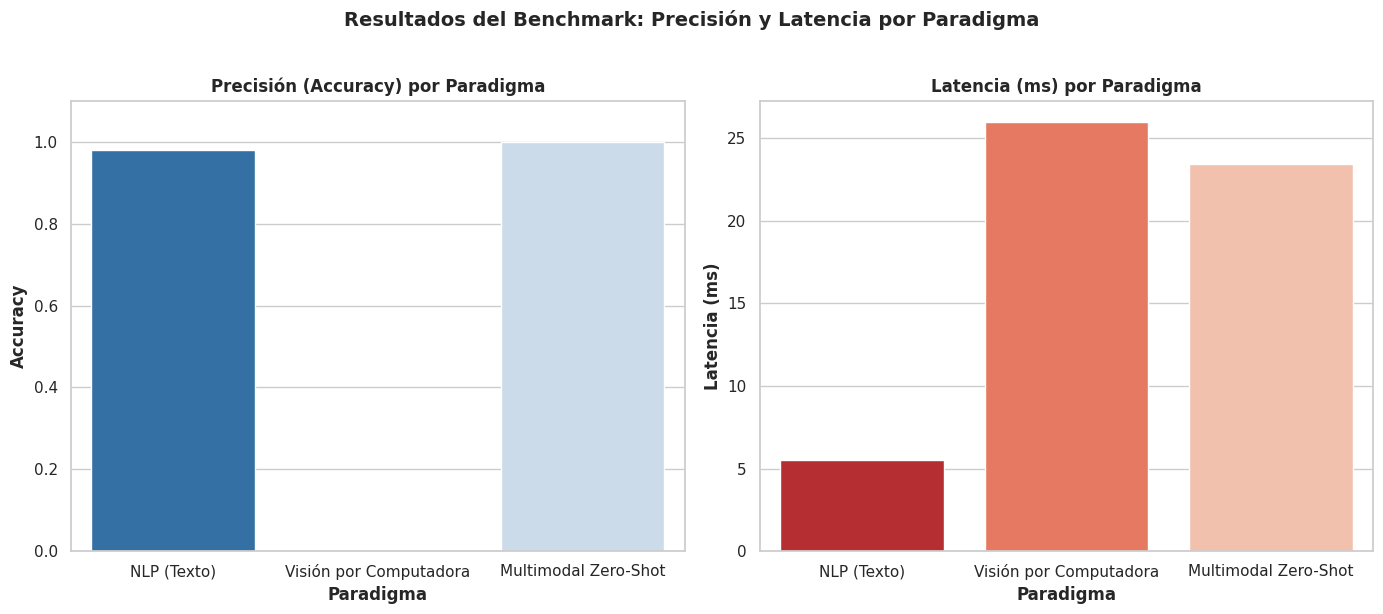

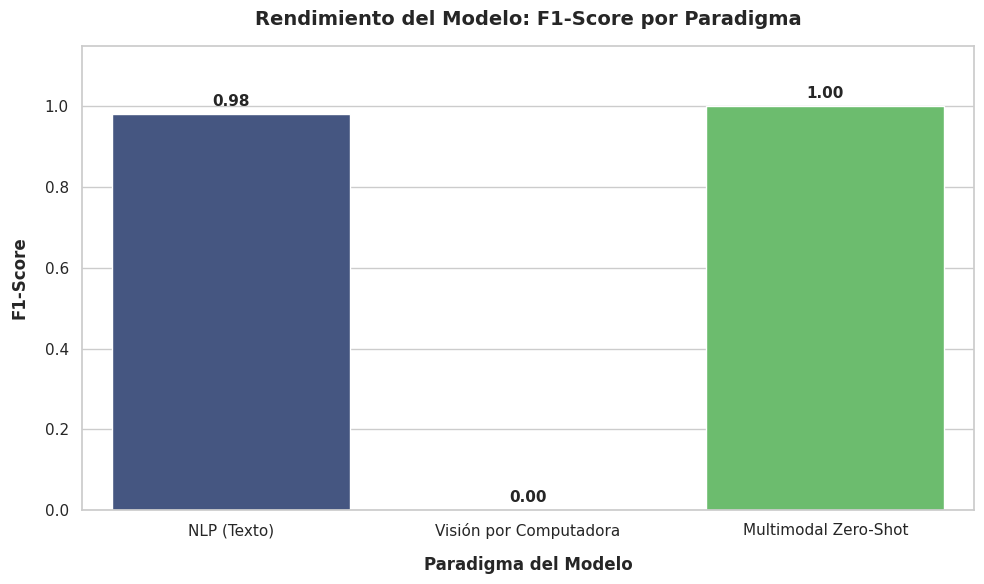

Resultados exportados correctamente a 'RESUMEN_COMPARACION_MODELOS.csv'


In [25]:
if __name__ == "__main__":
    main()